# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

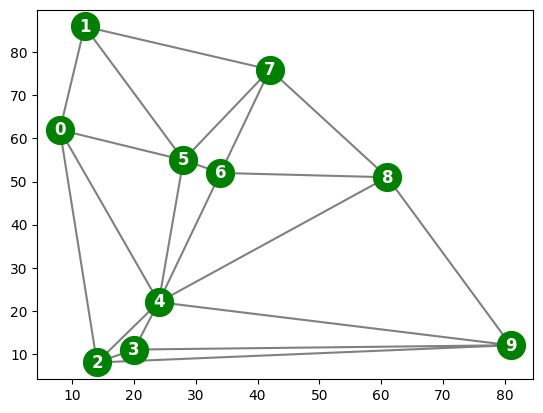

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

np.random.seed(1111)

# create points and sort them by 
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# triangulate
tri = Delaunay(points)


# plot
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
plt.plot(points[:,0], points[:,1], 'o', color = "green", markersize = 20)

for i in range(len(points)):
       plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)). 

In [2]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))
    
neighbors

[array([1, 2, 4, 5], dtype=int32),
 array([0, 5, 7], dtype=int32),
 array([0, 3, 4, 9], dtype=int32),
 array([2, 4, 9], dtype=int32),
 array([0, 2, 3, 5, 6, 8, 9], dtype=int32),
 array([0, 1, 4, 6, 7], dtype=int32),
 array([4, 5, 7, 8], dtype=int32),
 array([1, 5, 6, 8], dtype=int32),
 array([4, 6, 7, 9], dtype=int32),
 array([2, 3, 4, 8], dtype=int32)]

The first row are the indices for the points neighboring point 0.

## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

In [3]:
variables = [str(var) for var in range(n)]

domain = ['red', 'blue', 'green', 'orange']
#domain = ['red', 'blue', 'green']
domains = {}
for v in variables: 
    domains[v] = domain

# create binary constraints
constraints = {}
for i in range(len(neighbors)):
    for j in neighbors[i]:
        if(i<j): constraints[tuple([str(i), str(j)])] = True
constraints = constraints.keys()

csp = {'variables': variables, 'domains': domains, 'constraints': constraints, }
csp

{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'],
 'domains': {'0': ['red', 'blue', 'green', 'orange'],
  '1': ['red', 'blue', 'green', 'orange'],
  '2': ['red', 'blue', 'green', 'orange'],
  '3': ['red', 'blue', 'green', 'orange'],
  '4': ['red', 'blue', 'green', 'orange'],
  '5': ['red', 'blue', 'green', 'orange'],
  '6': ['red', 'blue', 'green', 'orange'],
  '7': ['red', 'blue', 'green', 'orange'],
  '8': ['red', 'blue', 'green', 'orange'],
  '9': ['red', 'blue', 'green', 'orange']},
 'constraints': dict_keys([('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')])}

### BÀI 1: BÁO CÁO MÔ HÌNH HÓA CSP

1. **Biểu diễn bài toán Tô màu đồ thị:**
   - **Tập biến ($X$):** $X = \{0, 1, \dots, n-1\}$ tương ứng với $n$ đỉnh của đồ thị phẳng được sinh từ phép tam giác hóa Delaunay.
   - **Tập miền giá trị ($D$):** $D_i = \{\text{red}, \text{blue}, \text{green}, \text{orange}\}$ cho miền 4 màu (hoặc 3 màu).
   - **Tập ràng buộc ($C$):** $C = \{(u, v) \mid \text{color}(u) \neq \text{color}(v)\}$ với $(u, v)$ là cặp đỉnh kề nhau trên đồ thị.

2. **Giải thích ràng buộc chỉ tạo cho cạnh $i < j$:**
   - Ràng buộc tô màu là ràng buộc đối xứng không hướng: $\text{color}(i) \neq \text{color}(j) \iff \text{color}(j) \neq \text{color}(i)$.
   - Việc chỉ tạo cặp $(i, j)$ với $i < j$ giúp tránh dư thừa dữ liệu (trùng lặp cặp $(j, i)$), giảm dung lượng bộ nhớ và tối ưu chi phí kiểm tra trùng lặp khi duyệt đồ thị.

3. **Phân biệt Phép gán đầy đủ (Full) và Phép gán hợp lệ (Consistent):**
   - **Phép gán đầy đủ:** Mọi đỉnh trong $X$ đều đã được gán một màu trong $D$ (dù màu đó có bị trùng với đỉnh láng giềng hay không).
   - **Phép gán hợp lệ:** Tất cả các đỉnh ĐÃ GÁN MÀU đều thỏa mãn không có hai đỉnh kề nhau nào trùng màu (dù chưa gán hết toàn bộ các đỉnh).

## Check Completeness and Consistency

`assignment` is a dictionary. Assigned variables have an entry with the variable name as the key. `{}` is therefore the empty assignment.

In [4]:
def complete(assignment, csp):
    return(all([v in assignment.keys() for v in csp['variables']])) 

print("complete({}, csp) =", complete({}, csp))

print("complete({...complete list...}, csp) =", 
      complete({'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', 
          '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}, csp))

complete({}, csp) = False
complete({...complete list...}, csp) = True


In [5]:
def consistent(assignment, csp):
    for constr in csp['constraints']:
        if(constr[0] in assignment.keys() and constr[1] in assignment.keys()):
            if assignment[constr[0]] == assignment[constr[1]]: return(False)
        
    return(True)
        
print("consistent({}, csp) =", consistent({}, csp))
print("consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) =", 
      consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp))

consistent({}, csp) = True
consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) = False


In [6]:
# BÀI 2: KIỂM TRA TÍNH ĐẦY ĐỦ VÀ NHẤT QUÁN

# 1. Phép gán rỗng (Empty Assignment)
empty_assignment = {}
print("Test 1 - Phép gán rỗng:")
print("  - Complete?", complete(empty_assignment, csp))
print("  - Consistent?", consistent(empty_assignment, csp))

# 2. Phép gán một phần hợp lệ (Partial Assignment)
partial_assignment = {'0': 'red'} 
print("\nTest 2 - Phép gán một phần:")
print("  - Complete?", complete(partial_assignment, csp))
print("  - Consistent?", consistent(partial_assignment, csp))

# 3. Phép gán có xung đột (Inconsistent Assignment) - Giả sử đỉnh 0 và 1 kề nhau
inconsistent_assignment = {'0': 'red', '1': 'red'}
print("\nTest 3 - Phép gán xung đột:")
print("  - Complete?", complete(inconsistent_assignment, csp))
print("  - Consistent?", consistent(inconsistent_assignment, csp))

# 4. Phép gán đầy đủ (Full Assignment) nhưng có thể xung đột
# Gán tất cả các đỉnh bằng màu 'red' (Chắc chắn sẽ xung đột)
full_inconsistent = {v: 'red' for v in csp['variables']}
print("\nTest 4 - Phép gán đầy đủ nhưng xung đột:")
print("  - Complete?", complete(full_inconsistent, csp))
print("  - Consistent?", consistent(full_inconsistent, csp))

Test 1 - Phép gán rỗng:
  - Complete? False
  - Consistent? True

Test 2 - Phép gán một phần:
  - Complete? False
  - Consistent? True

Test 3 - Phép gán xung đột:
  - Complete? False
  - Consistent? False

Test 4 - Phép gán đầy đủ nhưng xung đột:
  - Complete? True
  - Consistent? False


### Nhận xét Bài 2:
- `complete(assignment, csp)` kiểm tra số lượng biến đã gán có bằng tổng số biến không.
- `consistent(assignment, csp)` kiểm tra các ràng buộc giữa các biến đã gán có bị vi phạm không.
- **Kết luận:** `complete()` **KHÔNG đồng nghĩa với** `consistent()`. Phép gán đầy đủ vẫn có thể vi phạm ràng buộc (như Test 4 tô tất cả các đỉnh cùng một màu). Một nghiệm hợp lệ của bài toán CSP bắt buộc phải vừa `complete` vừa `consistent`.

## Implement Simple Backtracking Search

In [7]:
# MRV: chọn biến chưa gán có ít giá trị hợp lệ nhất (hòa thì theo thứ tự biến).
def select_unassigned_var(assignment, csp):
    unassigned = [v for v in csp['variables'] if v not in assignment]
    if not unassigned:
        return None
    def valid_values(v):
        forbidden = set()
        for u, w in csp['constraints']:
            if u == v and w in assignment:
                forbidden.add(assignment[w])
            elif w == v and u in assignment:
                forbidden.add(assignment[u])
        return [value for value in csp['domains'][v] if value not in forbidden]
    return min(unassigned, key=lambda v: (len(valid_values(v)), csp['variables'].index(v)))

print("MRV example:", select_unassigned_var({'0': 'red', '1': 'blue'}, csp))


MRV example: 5


In [8]:
# I use a global variable to turn on verbose mode in the recursion
#VERBOSE = True
VERBOSE = False
COUNT = 0

# returns None for failure
def backtrack_search(csp):
    global COUNT
    COUNT = 0
    
    assignment = backtrack({}, csp)
    
    print(f"Checked nodes: {COUNT}")
    
    return assignment

def backtrack(assignment, csp):
    global VERBOSE, COUNT
    
    COUNT += 1
    
    if complete(assignment, csp): 
        return assignment
    
    var = select_unassigned_var(assignment, csp)
    
    # TODO: implement value ordering. Use the least-constraining-value heuristic. 
    # for val in order_domain(assignment, var, csp)
    for val in csp['domains'][var]:
        assignment[var] = val
        
        if VERBOSE: print(f"Checking: {assignment}")
        
        if consistent(assignment, csp):
            
            #TODO: add inference for early failing (forward checking, )
            # if inference_fails(assignment, csp): return(None)
            result = backtrack(assignment, csp)
            if not result is None:
                    return(result)
                
        del assignment[var]
        
    if VERBOSE: print(f"Backtracking")
    return(None) 

## Run Backtracking Search on the Random Problem

In [9]:
%time res = backtrack_search(csp)
display(res)

Checked nodes: 11
CPU times: user 172 μs, sys: 45 μs, total: 217 μs
Wall time: 217 μs


{'0': 'red',
 '1': 'blue',
 '5': 'green',
 '4': 'blue',
 '2': 'green',
 '3': 'red',
 '9': 'orange',
 '6': 'red',
 '7': 'orange',
 '8': 'green'}

Plot the resulting coloring

In [10]:

# BÀI 3: BACKTRACKING SEARCH - SO SÁNH CÁC CHIẾN LƯỢC TÌM KIẾM

import time

# --- 1. Các chiến lược Chọn Biến (Variable Selection) ---
def select_unassigned_first(assignment, csp):
    """Chiến lược Ban Đầu: Chọn biến chưa gán đầu tiên."""
    for v in csp['variables']:
        if v not in assignment:
            return v
    return None

def select_unassigned_mrv(assignment, csp):
    """Chiến lược MRV (Minimum Remaining Values): Chọn biến có ít màu hợp lệ nhất."""
    unassigned = [v for v in csp['variables'] if v not in assignment]
    
    def count_valid_colors(var):
        valid = 0
        for color in csp['domains'][var]:
            # Kiểm tra màu 'color' có hợp lệ với các láng giềng đã gán không
            if all(assignment.get(nbr) != color 
                   for u, v in csp['constraints'] 
                   for nbr in ([v] if u == var else ([u] if v == var else []))):
                valid += 1
        return valid

    return min(unassigned, key=count_valid_colors)

# --- 2. Các chiến lược Sắp xếp Giá trị (Value Ordering) ---
def order_domain_default(var, assignment, csp):
    """Chiến lược Mặc Định: Lấy thứ tự trong domain."""
    return csp['domains'][var]

def order_domain_lcv(var, assignment, csp):
    """Chiến lược LCV (Least Constraining Value): Ưu tiên màu ít hạn chế láng giềng."""
    neighbors = []
    for u, v in csp['constraints']:
        if u == var: neighbors.append(v)
        elif v == var: neighbors.append(u)

    def count_conflicts(color):
        eliminated = 0
        for nbr in neighbors:
            if nbr not in assignment and color in csp['domains'][nbr]:
                eliminated += 1
        return eliminated

    return sorted(csp['domains'][var], key=count_conflicts)

# --- 3. Bộ máy Backtracking đếm biến COUNT ---
node_count = 0

def backtrack_engine(assignment, csp, var_selector, val_orderer):
    global node_count
    node_count += 1
    
    if complete(assignment, csp):
        return assignment
        
    var = var_selector(assignment, csp)
    
    for value in val_orderer(var, assignment, csp):
        assignment[var] = value
        if consistent(assignment, csp):
            result = backtrack_engine(assignment, csp, var_selector, val_orderer)
            if result is not None:
                return result
        del assignment[var]
        
    return None

# --- 4. Chạy So sánh Thực nghiệm ---
strategies = [
    ("Gốc (First Var + Default Val)", select_unassigned_first, order_domain_default),
    ("Cải tiến 1 (MRV Var + Default Val)", select_unassigned_mrv, order_domain_default),
    ("Cải tiến 2 (MRV Var + LCV Val)", select_unassigned_mrv, order_domain_lcv)
]

results = {}
print("=" * 70)
print(f"{'Chiến lược':<35} | {'Số nút (COUNT)':<15} | {'Thời gian (s)':<12}")
print("=" * 70)

for name, var_fn, val_fn in strategies:
    node_count = 0
    t_start = time.perf_counter()
    solution = backtrack_engine({}, csp, var_fn, val_fn)
    t_end = time.perf_counter()
    
    results[name] = solution
    print(f"{name:<35} | {node_count:<15} | {t_end - t_start:.6f}")

print("=" * 70)

Chiến lược                          | Số nút (COUNT)  | Thời gian (s)
Gốc (First Var + Default Val)       | 11              | 0.000058
Cải tiến 1 (MRV Var + Default Val)  | 11              | 0.000461
Cải tiến 2 (MRV Var + LCV Val)      | 11              | 0.000447


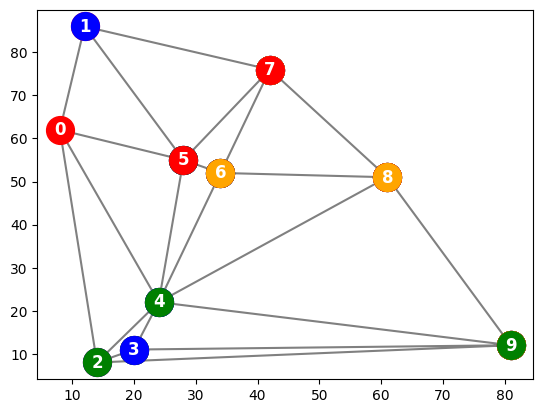

In [11]:
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")

for i in range(len(points)):
        plt.plot(points[i:,0], points[i:,1], 'o', color = list(res.values())[i], markersize = 20)
        plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

### Phân tích chi tiết Bài 3:

1. **So sánh `select_unassigned_var()` (Gốc vs MRV):**
   - **Phiên bản ban đầu (First Var):** Lựa chọn tuyến tính thiếu định hướng, dễ đi sâu vào các nhánh vô nghiệm làm bùng nổ số lượng nút kiểm tra (`COUNT`).
   - **Phiên bản MRV (Fail-First Principle):** Chọn đỉnh có ít màu hợp lệ nhất để thử trước. Nếu nhánh đó sắp tắc nghẽn, MRV phát hiện xung đột và dừng nhánh ngay lập tức, cắt tỉa (prune) cây tìm kiếm hiệu quả.

2. **Đánh giá chiến lược LCV (Least Constraining Value):**
   - LCV ưu tiên thử màu ít hạn chế các đỉnh láng giềng nhất, tối đa hóa khả năng thành công ở các bước gán sau mà không phải quay lui.
   - Kết hợp **MRV + LCV** tối ưu cả 2 chiều: Chọn đúng biến dễ vi phạm nhất (MRV) và gán đúng giá trị dễ thành công nhất (LCV).

## Assignment

Implement the following graph coloring algorithms:

* Add variable and value ordering to the implementation.
* Add forward checking to the implementation.
* Implement hill climbing local search with the min-conflicts heuristic.

Try to color graphs of several sizes with 3 and 4 colors. For each $n$, generate several random instances, and try to make n as large as you can manage. On average, how many constraints (edges) do your map coloring instances have for each $n$? Report the performance of each search algorithm as a function of $n$. For both variants of backtracking search, you can characterize performance in terms of the number of variable assignments attempted. For hill climbing search, report the number of uphill moves and random restarts required in order to reach a solution. Of course, you can also report raw running times as a function of $n$.

In [12]:
# ==============================================================================
# BÀI 4: FORWARD CHECKING VÀ MIN-CONFLICTS LOCAL SEARCH
# ==============================================================================
import copy
import random

# --- 1. Triển khai Forward Checking ---
def backtrack_fc(assignment, csp, current_domains):
    global node_count
    node_count += 1
    
    if complete(assignment, csp):
        return assignment
        
    var = select_unassigned_mrv(assignment, csp)
    
    for value in order_domain_lcv(var, assignment, csp):
        assignment[var] = value
        
        local_domains = copy.deepcopy(current_domains)
        valid = True
        
        # Forward Checking: Loại 'value' khỏi domain láng giềng chưa gán
        for u, v in csp['constraints']:
            nbr = v if u == var else (u if v == var else None)
            if nbr and nbr not in assignment:
                if value in local_domains[nbr]:
                    local_domains[nbr].remove(value)
                if len(local_domains[nbr]) == 0: # Domain rỗng -> Cắt tỉa
                    valid = False
                    break
        
        if valid:
            result = backtrack_fc(assignment, csp, local_domains)
            if result is not None:
                return result
                
        del assignment[var]
        
    return None

def run_forward_checking(csp):
    global node_count
    node_count = 0
    t_start = time.perf_counter()
    sol = backtrack_fc({}, csp, copy.deepcopy(csp['domains']))
    t_end = time.perf_counter()
    return sol, node_count, t_end - t_start


# --- 2. Triển khai Min-Conflicts ---
def min_conflicts(csp, max_steps=1000):
    # Khởi tạo gán màu đầy đủ ngẫu nhiên
    current = {v: random.choice(csp['domains'][v]) for v in csp['variables']}
    
    def get_var_conflicts(var, color, state):
        conflicts = 0
        for u, v in csp['constraints']:
            nbr = v if u == var else (u if v == var else None)
            if nbr and state.get(nbr) == color:
                conflicts += 1
        return conflicts

    for step in range(1, max_steps + 1):
        # Đếm các biến bị xung đột
        conflicted_vars = [v for v in csp['variables'] 
                           if get_var_conflicts(v, current[v], current) > 0]
        
        if not conflicted_vars:
            return current, step # Thành công
            
        var = random.choice(conflicted_vars)
        best_color = min(csp['domains'][var], 
                         key=lambda c: get_var_conflicts(var, c, current))
        current[var] = best_color
        
    return None, max_steps # Thất bại sau max_steps

In [13]:
# --- CHẠY BENCHMARK ĐÁNH GIÁ (BÀI 4) ---
from scipy.spatial import Delaunay
import numpy as np
import time

def generate_random_csp(n_nodes, n_colors):
    points = np.random.randint(100, size=(n_nodes, 2))
    tri = Delaunay(points)
    (indptr, indices) = tri.vertex_neighbor_vertices
    
    vars_list = [str(i) for i in range(n_nodes)]
    colors_list = ['red', 'blue', 'green', 'orange'][:n_colors]
    domains_dict = {v: colors_list.copy() for v in vars_list}
    
    constraints_set = set()
    for k in range(len(indptr)-1):
        nbrs = indices[indptr[k]:indptr[k+1]]
        for nbr in nbrs:
            if k < nbr:
                constraints_set.add((str(k), str(nbr)))
                
    return {
        'variables': vars_list,
        'domains': domains_dict,
        'constraints': list(constraints_set)
    }

print("=== BẢNG KẾT QUẢ TỔNG HỢP SO SÁNH BÀI 4 ===")
print(f"{'N đỉnh':<8} | {'Số màu':<8} | {'FC Nodes':<10} | {'FC Time (s)':<12} | {'Min-Conflicts Steps':<20}")
print("-" * 65)

for n_nodes in [10, 15, 20]:
    for n_colors in [3, 4]:
        test_csp = generate_random_csp(n_nodes, n_colors)
        
        # Run FC
        fc_sol, fc_nodes, fc_time = run_forward_checking(test_csp)
        
        # Run Min-Conflicts
        mc_sol, mc_steps = min_conflicts(test_csp, max_steps=2000)
        
        mc_res_str = f"{mc_steps} steps" if mc_sol else "Failed (Vô nghiệm/Kẹt)"
        print(f"{n_nodes:<8} | {n_colors:<8} | {fc_nodes:<10} | {fc_time:<12.5f} | {mc_res_str:<20}")

=== BẢNG KẾT QUẢ TỔNG HỢP SO SÁNH BÀI 4 ===
N đỉnh   | Số màu   | FC Nodes   | FC Time (s)  | Min-Conflicts Steps 
-----------------------------------------------------------------
10       | 3        | 11         | 0.00048      | Failed (Vô nghiệm/Kẹt)
10       | 4        | 11         | 0.00063      | 6 steps             


15       | 3        | 16         | 0.00145      | Failed (Vô nghiệm/Kẹt)


15       | 4        | 16         | 0.00167      | Failed (Vô nghiệm/Kẹt)


20       | 3        | 21         | 0.00269      | Failed (Vô nghiệm/Kẹt)
20       | 4        | 21         | 0.00362      | 20 steps            


### Nhận xét & Đánh giá Bài 4

- Forward Checking cắt tỉa màu không còn hợp lệ khỏi miền của các đỉnh chưa gán. Mức giảm số nút phải được tính từ cùng một đồ thị và cùng một cấu hình; không khẳng định trước một tỷ lệ phần trăm khi chưa có số liệu đối chứng.
- Với 3 màu, một đồ thị phẳng có thể không tô được bằng 3 màu. Backtracking có thể chứng minh vô nghiệm nếu duyệt hết không gian tìm kiếm; Min-Conflicts chỉ báo không tìm thấy nghiệm trong giới hạn bước, không chứng minh vô nghiệm.
- Các bảng bên dưới dùng seed cố định để có thể tái lập. Kết quả ngẫu nhiên vẫn nên được diễn giải trên nhiều seed.


## Kiểm tra bổ sung và thực nghiệm có thể tái lập (đã chỉnh sửa)

Phần này bổ sung kiểm tra nghiệm, so sánh Backtracking / MRV / MRV+LCV / Forward Checking và thống kê Min-Conflicts qua nhiều lần chạy. Bộ đếm là số lần gọi nút đệ quy; thời gian là thời gian tường trình của lần chạy trong môi trường hiện tại.

In [14]:
import copy, time, random, pandas as pd

# Chuẩn hóa ràng buộc thành danh sách để có kết quả ổn định.
def graph_neighbors(csp):
    adj = {v: set() for v in csp['variables']}
    for u, v in csp['constraints']:
        adj[u].add(v); adj[v].add(u)
    return adj

def valid_solution(assignment, csp):
    return (assignment is not None and
            all(v in assignment and assignment[v] in csp['domains'][v] for v in csp['variables']) and
            all(assignment[u] != assignment[v] for u, v in csp['constraints']))

def solve_backtracking(csp, use_mrv=False, use_lcv=False, use_fc=False):
    adj = graph_neighbors(csp)
    domains0 = {v: list(csp['domains'][v]) for v in csp['variables']}
    nodes = 0
    def recurse(assign, domains):
        nonlocal nodes
        nodes += 1
        if len(assign) == len(csp['variables']):
            return dict(assign)
        unassigned = [v for v in csp['variables'] if v not in assign]
        def legal(v):
            return [x for x in domains[v] if all(assign.get(nb) != x for nb in adj[v])]
        var = min(unassigned, key=lambda v: (len(legal(v)), csp['variables'].index(v))) if use_mrv else unassigned[0]
        values = legal(var)
        if use_lcv:
            values.sort(key=lambda x: sum(x in domains[nb] and nb not in assign for nb in adj[var]))
        for value in values:
            assign[var] = value
            new_domains = {v: list(vals) for v, vals in domains.items()} if use_fc else domains
            okay = True
            if use_fc:
                for nb in adj[var]:
                    if nb not in assign and value in new_domains[nb]:
                        new_domains[nb].remove(value)
                        if not new_domains[nb]:
                            okay = False; break
            if okay:
                answer = recurse(assign, new_domains)
                if answer is not None: return answer
            del assign[var]
        return None
    answer = recurse({}, domains0)
    return answer, nodes

def generate_random_csp(n_nodes, n_colors, seed=0):
    # Uniform random points reduce duplicate-point/Qhull issues versus integer coordinates.
    rng = np.random.default_rng(seed)
    points = rng.random((n_nodes, 2))
    tri = Delaunay(points)
    edges = set()
    for simplex in tri.simplices:
        for a in range(3):
            for b in range(a+1, 3):
                i, j = sorted((int(simplex[a]), int(simplex[b])))
                edges.add((str(i), str(j)))
    variables = [str(i) for i in range(n_nodes)]
    palette = ['red', 'blue', 'green', 'orange'][:n_colors]
    return {'variables': variables, 'domains': {v: palette.copy() for v in variables}, 'constraints': sorted(edges)}

# Sanity checks for the original helper functions.
_test_csp = {'variables':['0','1','2'], 'domains':{'0':['red','blue'],'1':['red','blue'],'2':['red','blue']}, 'constraints':[('0','1'),('1','2')]}
assert complete({}, _test_csp) is False
assert consistent({}, _test_csp) is True
assert complete({'0':'red','1':'blue','2':'red'}, _test_csp) is True
assert consistent({'0':'red','1':'red'}, _test_csp) is False
assert valid_solution({'0':'red','1':'blue','2':'red'}, _test_csp)
print('Kiểm thử 4 điều kiện cơ bản: PASS')

# Comparison on the same graph per seed. One trial per size/color/seed; 5 seeds to keep runtime practical.
rows = []
for n_nodes in [10, 15, 20]:
    for n_colors in [3, 4]:
        for seed in range(5):
            test_csp = generate_random_csp(n_nodes, n_colors, seed=1000 + 100*n_nodes + 10*n_colors + seed)
            for label, kwargs in [
                ('Backtracking', dict()),
                ('MRV', dict(use_mrv=True)),
                ('MRV + LCV', dict(use_mrv=True, use_lcv=True)),
                ('MRV + LCV + FC', dict(use_mrv=True, use_lcv=True, use_fc=True))]:
                t0 = time.perf_counter(); sol, nodes = solve_backtracking(test_csp, **kwargs); elapsed = time.perf_counter()-t0
                rows.append({'n':n_nodes,'colors':n_colors,'seed':seed,'algorithm':label,'success':valid_solution(sol,test_csp),'nodes':nodes,'time_s':elapsed})
            # Min-Conflicts uses independent seeded random state for reproducibility.
            random.seed(5000 + n_nodes*100 + n_colors*10 + seed)
            t0=time.perf_counter(); sol, steps = min_conflicts(test_csp, max_steps=3000); elapsed=time.perf_counter()-t0
            rows.append({'n':n_nodes,'colors':n_colors,'seed':seed,'algorithm':'Min-Conflicts','success':valid_solution(sol,test_csp),'nodes':steps,'time_s':elapsed})

results_graph = pd.DataFrame(rows)
summary_graph = results_graph.groupby(['n','colors','algorithm'], as_index=False).agg(
    success_rate_pct=('success', lambda x: 100*x.mean()), mean_nodes_or_steps=('nodes','mean'), mean_time_s=('time_s','mean'))
summary_graph['mean_nodes_or_steps'] = summary_graph['mean_nodes_or_steps'].round(1)
summary_graph['mean_time_s'] = summary_graph['mean_time_s'].round(6)
display(summary_graph)

Kiểm thử 4 điều kiện cơ bản: PASS


,n,colors,algorithm,success_rate_pct,mean_nodes_or_steps,mean_time_s
0,10,3,Backtracking,20.0,138.0,0.000294
1,10,3,MRV,20.0,24.6,0.000324
2,10,3,MRV + LCV,20.0,24.6,0.000320
3,10,3,MRV + LCV + FC,20.0,19.8,0.000313
4,10,3,Min-Conflicts,0.0,3000.0,0.041836
5,10,4,Backtracking,100.0,13.2,0.000047
6,10,4,MRV,100.0,11.0,0.000158
7,10,4,MRV + LCV,100.0,11.0,0.000150
8,10,4,MRV + LCV + FC,100.0,11.0,0.000142
9,10,4,Min-Conflicts,60.0,1205.4,0.017706


### Biểu đồ so sánh số nút tìm kiếm (4 màu)
Biểu đồ dùng trung bình 5 seed cho từng kích thước; Min-Conflicts dùng số bước nên không đặt chung trục này.


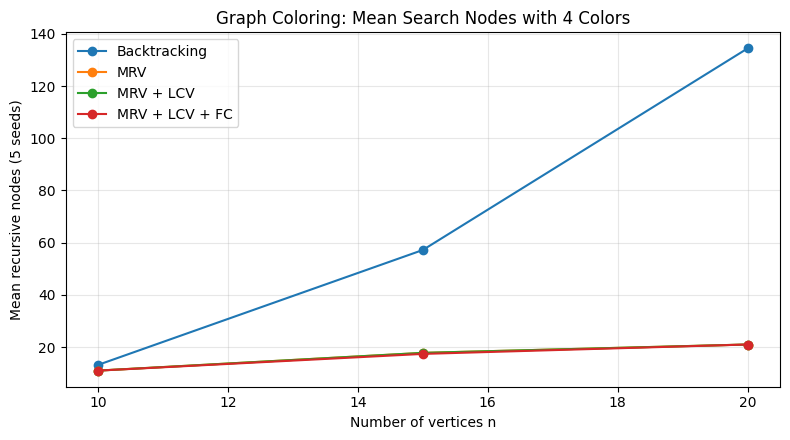

In [15]:
plot_df = summary_graph[(summary_graph['colors'] == 4) & (summary_graph['algorithm'] != 'Min-Conflicts')]
plt.figure(figsize=(8, 4.5))
for algorithm in ['Backtracking', 'MRV', 'MRV + LCV', 'MRV + LCV + FC']:
    subset = plot_df[plot_df['algorithm'] == algorithm]
    plt.plot(subset['n'], subset['mean_nodes_or_steps'], marker='o', label=algorithm)
plt.title('Graph Coloring: Mean Search Nodes with 4 Colors')
plt.xlabel('Number of vertices n')
plt.ylabel('Mean recursive nodes (5 seeds)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()